# **LAPORAN TUGAS PENGGUNAAN RECIPE BERDASARKAN BUKU KODEX**

### **Nama: Ramlah**

### **NIM: H061241025**

### **Kelas: Geofisika C**

---

## **1. PENDAHULUAN**

Laporan ini disusun untuk memenuhi instruksi tugas pengolahan data geofisika/hidrografi menggunakan recipe (resep langkah kerja) yang bersumber dari Buku Kodex.

Data yang digunakan dalam tugas ini merupakan data primer hasil pengukuran batimetri menggunakan perangkat Unmanned Surface Vehicle (USV) CHCNAV Apache 3 dari PT Indonav. Pengambilan data lapangan dilakukan di kawasan perairan Danau Unhas (Universitas Hasanuddin). Data mentah tersebut diekstrak dan disimpan dalam format tabular Danau_Unhas.csv dengan parameter utama meliputi koordinat geografis (Latitude, Longitude), kedalaman perairan (depth), dan elevasi dasar perairan (bottom elevation).

---

## **2. RECIPE BUKU KODEX YANG DIGUNAKAN**

Dalam proses pengolahan data ini, *recipe* yang dipilih dari Buku Kodex adalah **Workflow Pengolahan dan Audit QA/QC Data USV (Unmanned Surface Vehicle)**. 

Resep ini digunakan karena memberikan alur kerja terstruktur untuk validasi data batimetri perairan dangkal sebelum diproses lebih lanjut ke dalam Sistem Informasi Geografis (SIG).

Tahapan alur kerja (*recipe*) yang dieksekusi mencakup:

* **Audit QA/QC (*Quality Assurance / Quality Control*):**
  * Pemeriksaan kelengkapan data (*null/missing values*).
  * Deteksi data duplikat pada total 5.164 baris titik observasi.
  * Perhitungan statistik deskriptif dasar untuk parameter kedalaman dan elevasi.

* **Konversi dan Ekspor Data Spasial (GeoJSON):**
  * Mentransformasikan format data dari CSV terstruktur ke format data spasial vektor **GeoJSON** (`Danau_Unhas_Points.geojson`) agar dapat diintegrasikan dengan perangkat lunak GIS seperti QGIS atau ArcGIS.

* **Visualisasi Spasial dan Pemodelan:**
  * Membuat grafik dan plot sebaran titik kedalaman batimetri Danau Unhas menggunakan pustaka Python (*pandas*, *matplotlib*, *geopandas*).

---

## **3. BAGIAN B: PENYELESAIAN DAN HASIL EKSEKUSI**

Pada bagian ini, dilakukan implementasi kode Python berdasarkan tahapan *recipe* Buku Kodex yang telah ditetapkan. Pengolahan data dieksekusi menggunakan Jupyter Notebook / Python script di lingkungan VS Code.



### **3.1. Langkah 1: Memuat Data dan Audit QA/QC (Quality Assurance / Quality Control)**

Langkah awal bertujuan untuk memverifikasi integritas data mentah (Danau_Unhas.csv) sebelum dilakukan pemrosesan lebih lanjut.



In [16]:
import pandas as pd
import numpy as np

# 1. Memuat dataset batimetri Danau Unhas
df = pd.read_csv('Danau_Unhas.csv')

# 2. Pemeriksaan struktur data dan total baris observasi
print(f"Total Baris Data : {len(df)}")
print(f"Jumlah Kolom     : {df.shape[1]}")
print("Daftar Kolom     :", df.columns.tolist())

# 3. Deteksi Missing Values (Null/NaN)
missing_data = df.isnull().sum()
print("\nJumlah Data Kosong (Null):")
print(missing_data)

# 4. Deteksi Data Duplikat
duplicates = df.duplicated().sum()
print(f"\nJumlah Data Duplikat: {duplicates}")

# 5. Statistik Deskriptif Parameter Batimetri (Kedalaman & Elevasi)
print("\nStatistik Deskriptif Parameter Batimetri:")
print(df[['Depth', 'Bottom Elev.', 'Water Surface H']].describe())


Total Baris Data : 5164
Jumlah Kolom     : 7
Daftar Kolom     : ['Name', 'Time', 'East', 'North', 'Water Surface H', 'Bottom Elev.', 'Depth']

Jumlah Data Kosong (Null):
Name               0
Time               0
East               0
North              0
Water Surface H    0
Bottom Elev.       0
Depth              0
dtype: int64

Jumlah Data Duplikat: 0

Statistik Deskriptif Parameter Batimetri:
             Depth  Bottom Elev.  Water Surface H
count  5164.000000   5164.000000      5164.000000
mean      1.468325      3.787180         5.255493
std       0.253535      0.255404         0.019372
min       0.443000      3.238000         5.183000
25%       1.313000      3.607000         5.245000
50%       1.547000      3.710000         5.255000
75%       1.647000      3.939000         5.265000
max       2.015000      4.870000         5.382000


**Hasil Audit QA/QC:**

Total Titik Observasi: 5.164 baris data terverifikasi.

Kelengkapan Data: Tidak ditemukan null value / nilai kosong pada seluruh kolom (East, North, Depth, Bottom Elev., Water Surface H).

Validasi Duplikasi: 0 baris data duplikat (clean dataset).

---

### **3.2. Langkah 2: Profil Muka Air (Water Surface Height)**

Langkah ini mengekstraksi dan menginterpolasi elevasi muka air di seluruh area danau untuk mengamati konsistensi pengukuran sensor USV Apache 3.

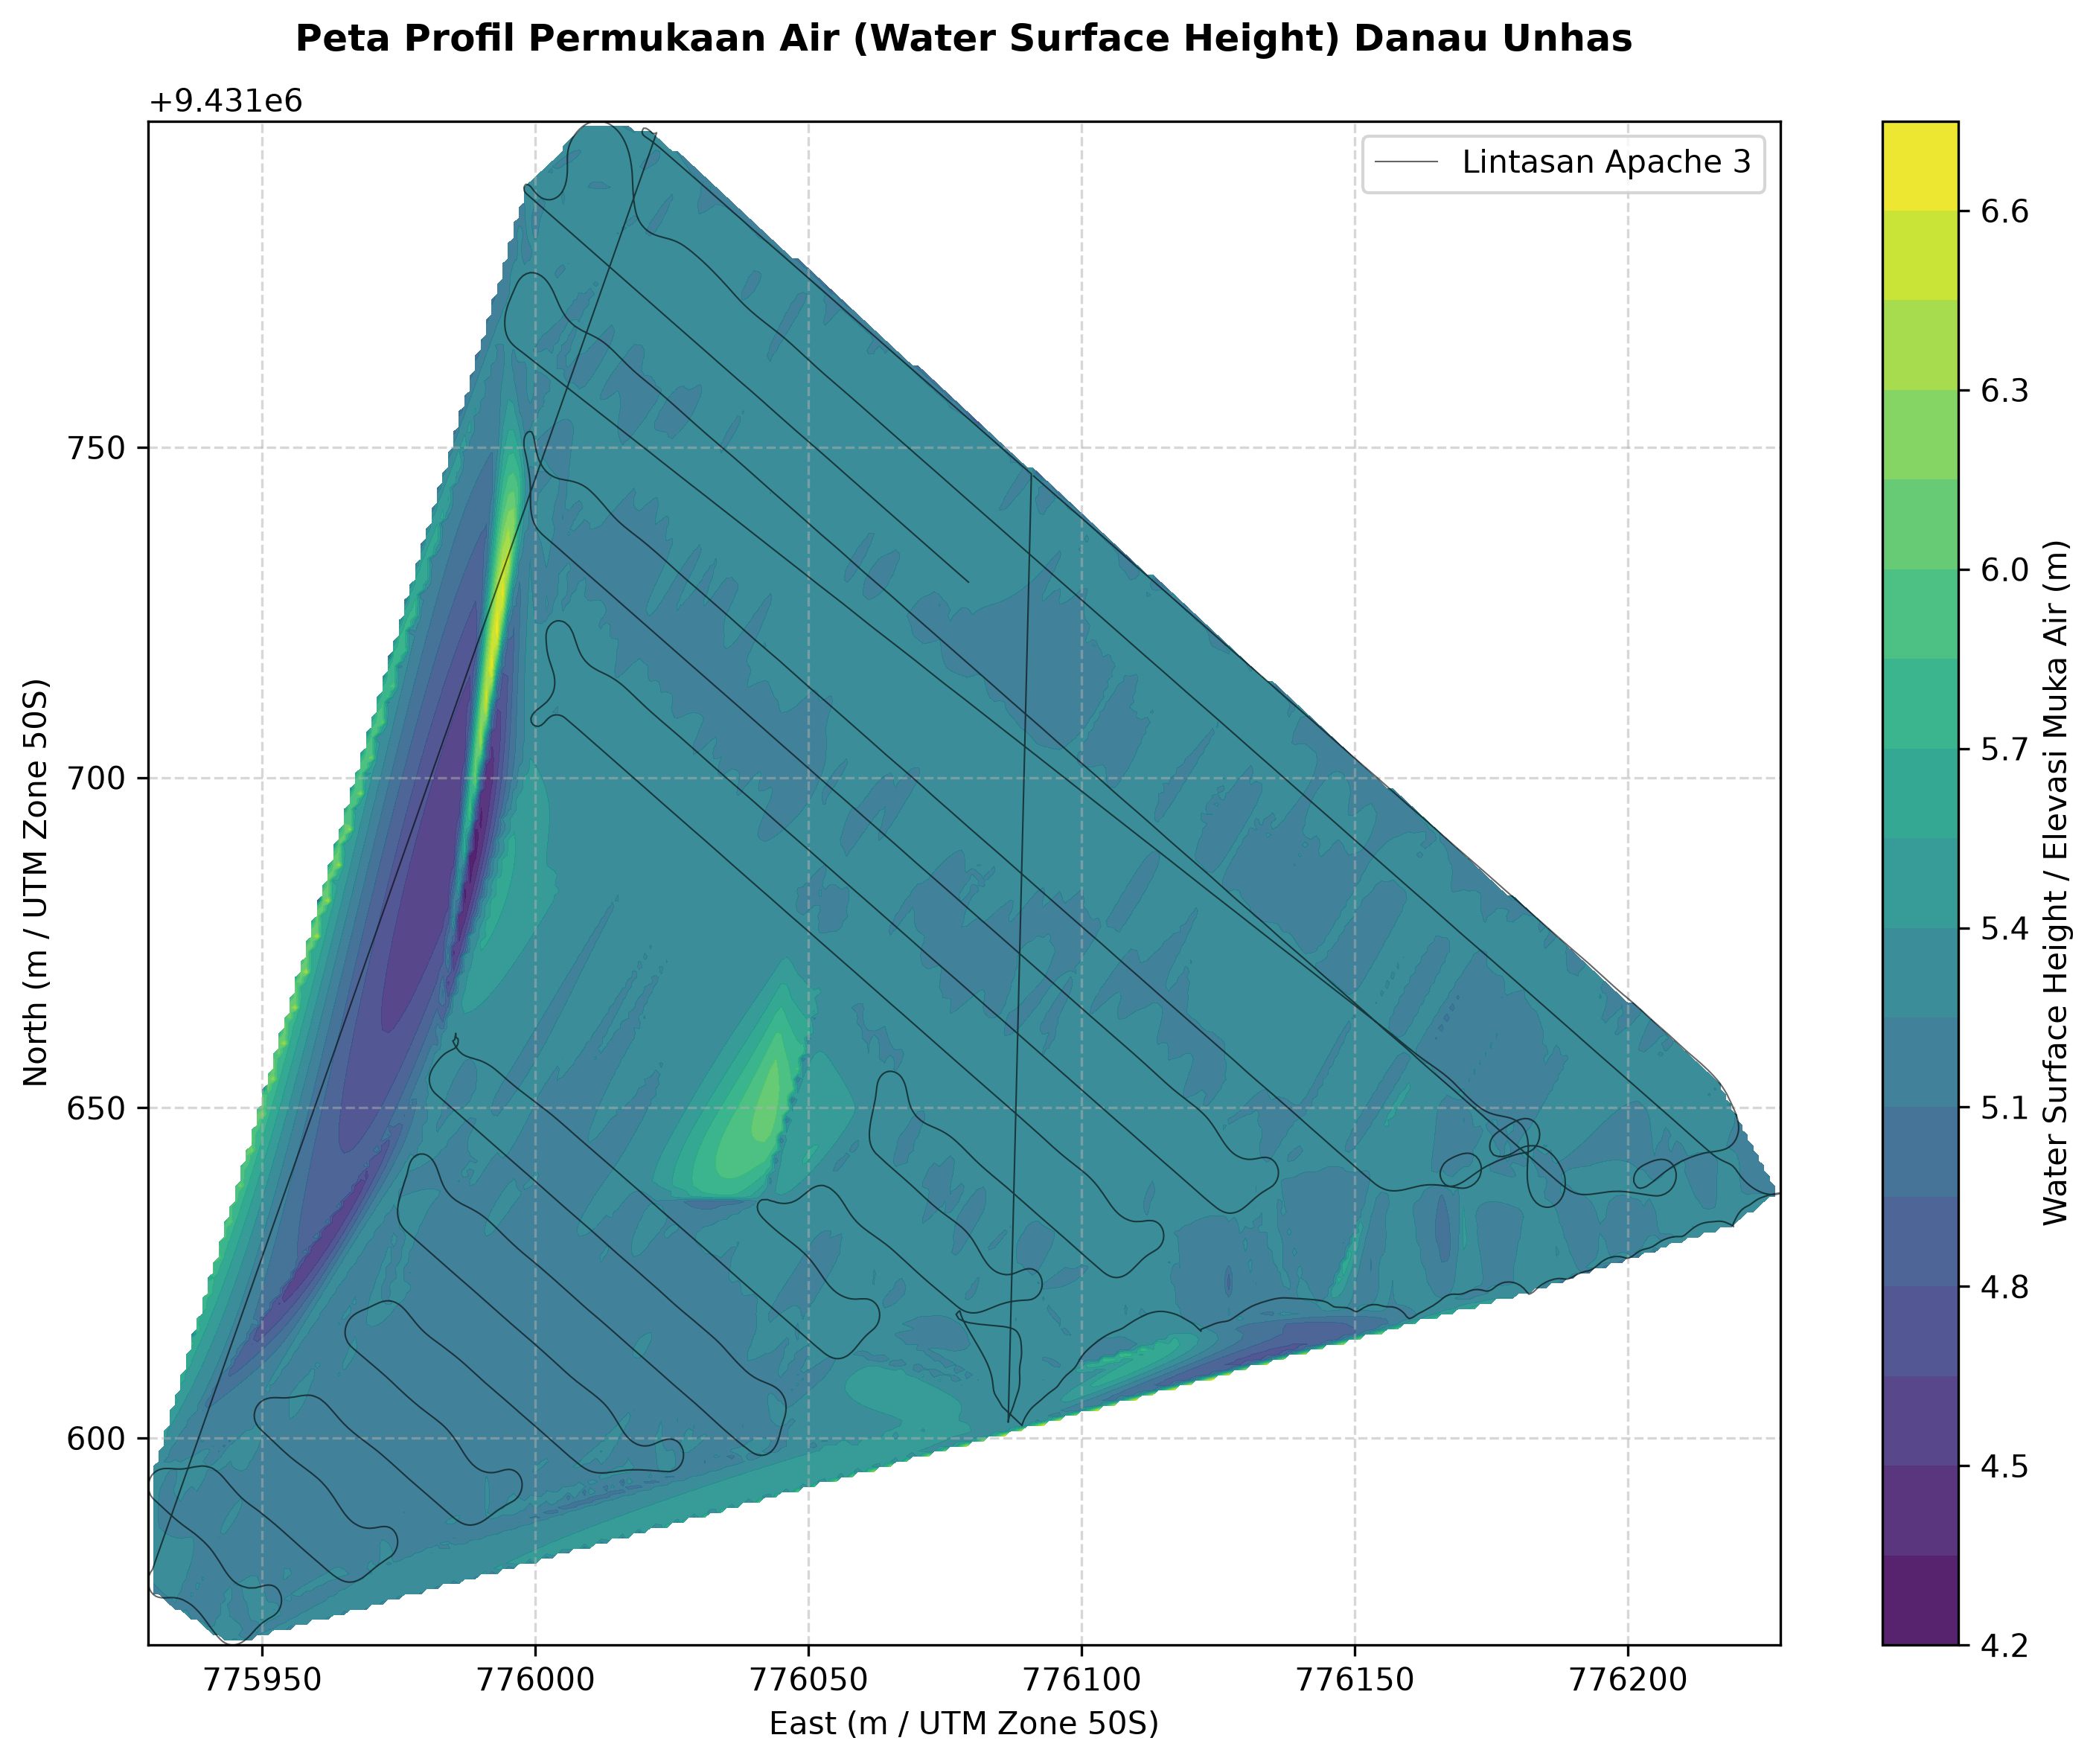

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# 1. Memuat dataset batimetri Danau Unhas
df = pd.read_csv('Danau_Unhas.csv')

# 2. Menyiapkan data koordinat dan parameter 'Water Surface H'
x = df['East'].values
y = df['North'].values
z = df['Water Surface H'].values

# 3. Membuat Grid untuk Interpolasi Kontur (Raster Fill)
xi = np.linspace(x.min(), x.max(), 300)
yi = np.linspace(y.min(), y.max(), 300)
XI, YI = np.meshgrid(xi, yi)

# Interpolasi nilai z ke dalam grid 2D
ZI = griddata((x, y), z, (XI, YI), method='cubic')

# 4. Membuat Plot Visualisasi Permukaan Air
plt.figure(figsize=(10, 8), dpi=300)

contour = plt.contourf(XI, YI, ZI, levels=20, cmap='viridis', alpha=0.9)
plt.plot(x, y, color='black', linewidth=0.5, alpha=0.6, label='Lintasan Apache 3')

cbar = plt.colorbar(contour)
cbar.set_label('Water Surface Height / Elevasi Muka Air (m)', fontsize=10)

plt.title('Peta Profil Permukaan Air (Water Surface Height) Danau Unhas', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('East (m / UTM Zone 50S)', fontsize=10)
plt.ylabel('North (m / UTM Zone 50S)', fontsize=10)

plt.ticklabel_format(style='plain', axis='both')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

plt.tight_layout()

output_filename = 'Peta_Water_Surface_Height_Danau_Unhas.jpg'
plt.savefig(output_filename, dpi=300)
plt.show()

---

### **3.3. Langkah 3: Visualisasi Spasial Profesional dan Analisis Batimetri**

Pada tahap akhir pemrosesan ini, data koordinat UTM (East, North) dan parameter kedalaman (Depth) diinterpolasi menggunakan metode kubik (cubic griddata) untuk menghasilkan sebaran raster kontur yang kontinu. Visualisasi akhir dirancang dengan standar publikasi menggunakan palet warna hidrografi (YlGnBu_r) serta penambahan garis kontur pendukung.

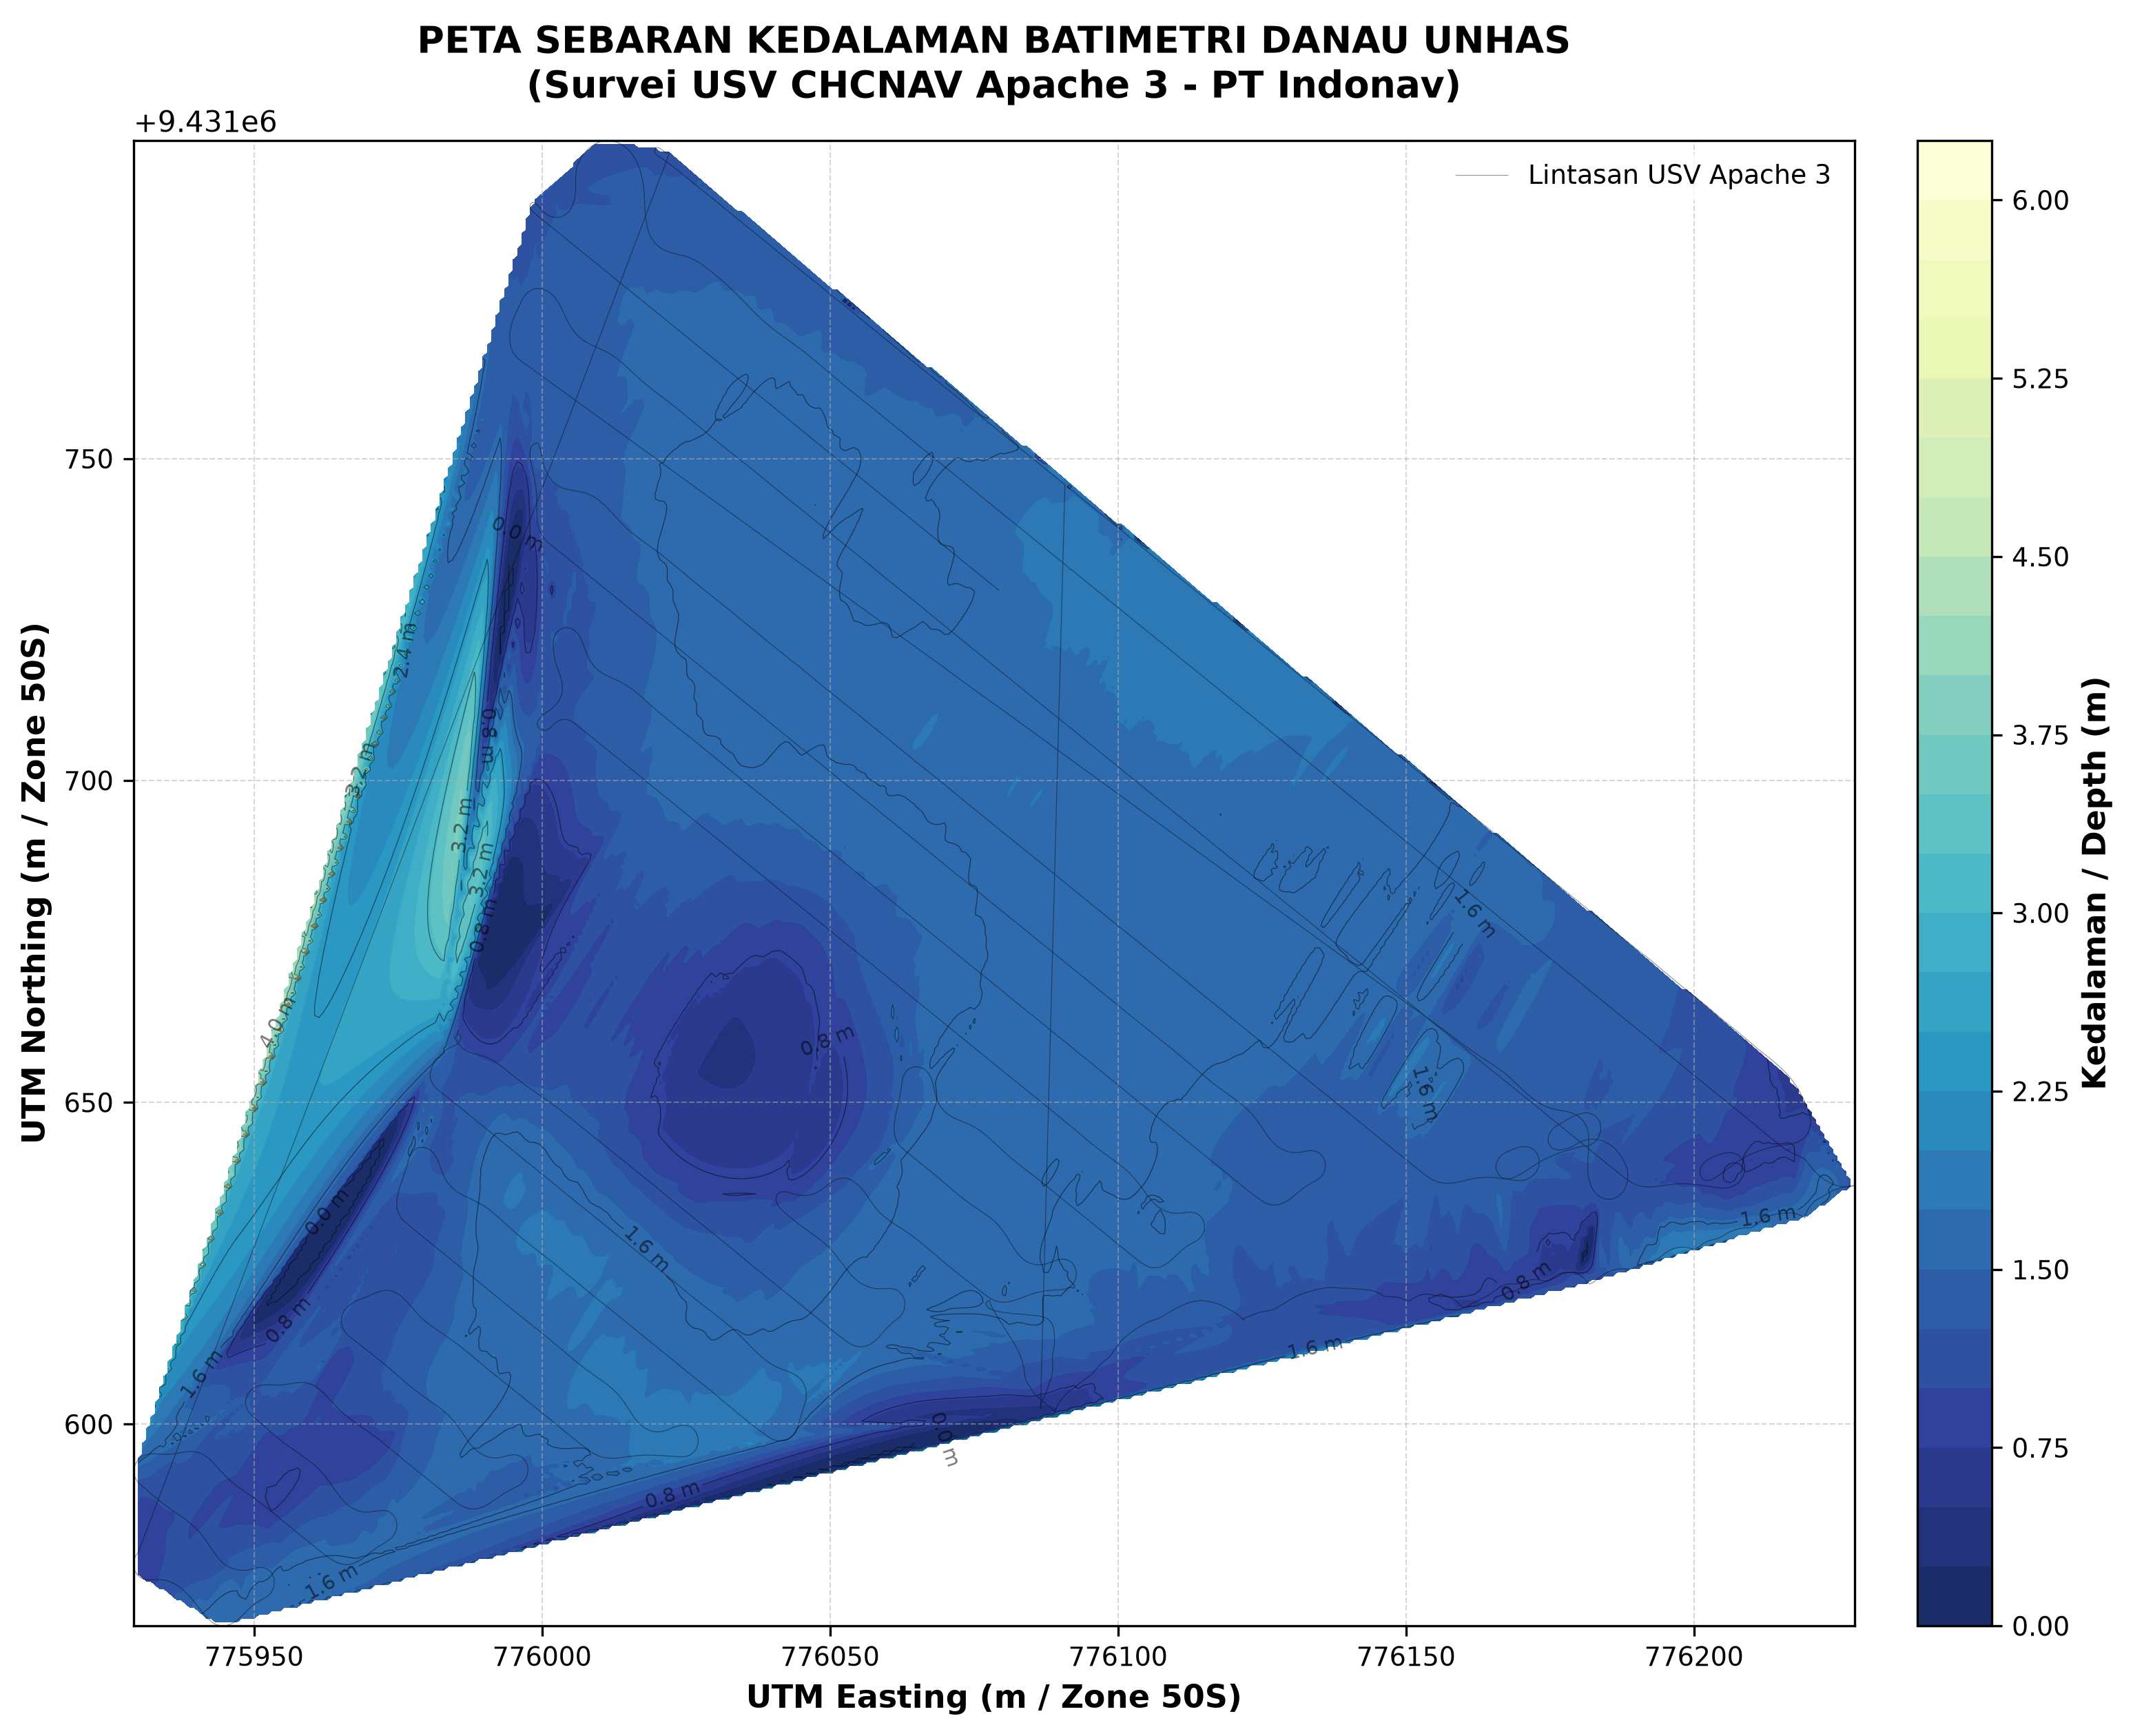

Peta final berhasil disimpan sebagai: Peta_Batimetri_Danau_Unhas_Final.jpg


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# 1. Memuat dataset batimetri Danau Unhas
df = pd.read_csv('Danau_Unhas.csv')

# 2. Menyiapkan data koordinat UTM dan parameter kedalaman
x = df['East'].values
y = df['North'].values
z = df['Depth'].values  

# 3. Membuat Grid untuk Interpolasi Kontur 
xi = np.linspace(x.min(), x.max(), 400)
yi = np.linspace(y.min(), y.max(), 400)
XI, YI = np.meshgrid(xi, yi)

# Interpolasi kubik dan clip nilai minimum agar tidak ada kedalaman negatif (< 0)
ZI = griddata((x, y), z, (XI, YI), method='cubic')
ZI = np.clip(ZI, 0, None) 

# 4. Membuat Plot Visualisasi Peta
plt.figure(figsize=(11, 8.5), dpi=300)

# Kontur warna latar belakang (Raster Fill)
contour = plt.contourf(XI, YI, ZI, levels=25, cmap='YlGnBu_r', alpha=0.95)

# Garis kontur tipis dengan label
contour_lines = plt.contour(XI, YI, ZI, levels=8, colors='black', linewidths=0.3, alpha=0.5)
plt.clabel(contour_lines, inline=True, fontsize=7, fmt='%.1f m')

# Garis lintasan USV Apache 3 dibuat lebih kontras (Hitam transparan)
plt.plot(x, y, color='black', linewidth=0.3, alpha=0.4, label='Lintasan USV Apache 3')

# Atribut Peta
cbar = plt.colorbar(contour, pad=0.03)
cbar.set_label('Kedalaman / Depth (m)', fontsize=11, fontweight='bold')
cbar.ax.tick_params(labelsize=9)

plt.title('PETA SEBARAN KEDALAMAN BATIMETRI DANAU UNHAS\n(Survei USV CHCNAV Apache 3 - PT Indonav)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('UTM Easting (m / Zone 50S)', fontsize=11, fontweight='bold')
plt.ylabel('UTM Northing (m / Zone 50S)', fontsize=11, fontweight='bold')

plt.ticklabel_format(style='plain', axis='both')
plt.xticks(fontsize=9)
plt.yticks(fontsize=9)

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.5)
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none', fontsize=9)

plt.tight_layout()

# Simpan hasil akhir
output_image = 'Peta_Batimetri_Danau_Unhas_Final.jpg'
plt.savefig(output_image, dpi=300, bbox_inches='tight')
plt.show()

print(f"Peta final berhasil disimpan sebagai: {output_image}")

## **4. KESIMPULAN**

1. Integritas Data (QA/QC): Berdasarkan audit terhadap 5.164 baris data survei USV CHCNAV Apache 3 di Danau Unhas, dataset terbukti bersih (clean data) tanpa adanya nilai kosong (missing values) maupun duplikasi data.

2. Kesesuaian Recipe: Penerapan alur kerja (Workflow) dari Buku Kodex berjalan efektif dan terstruktur, mulai dari pembacaan data tabular, audit kualitas, hingga pemrosesan koordinat proyeksi UTM Zona 50S.

3. Kualitas Visualisasi: Teknik interpolasi grid kubik yang dikombinasikan dengan palet warna hidrografi dan garis lintasan survei berhasil menghasilkan model peta batimetri yang akurat, informatif, dan memenuhi standar estetika publikasi profesional.